In [2]:
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

# sube por las carpetas hasta encontrar la raíz del repo (la que tiene milk10k_pipeline/)
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "milk10k_pipeline" / "config.py").is_file())
sys.path.insert(0, str(ROOT))

np.set_printoptions(precision=1, suppress=True)
print("ROOT:", ROOT)

ROOT: C:\Users\Dell\OneDrive\Desktop\EADA\4th Year\Computer Vision & Speech Recognition\Milk10k-project


In [3]:
image = np.array([
    [100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100],
    [100, 100,  10,  10,  10],
    [100, 100,  10,  10,  10],
    [100, 100,  10,  10,  10],
], dtype=float)

image

array([[100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100.],
       [100., 100.,  10.,  10.,  10.],
       [100., 100.,  10.,  10.,  10.],
       [100., 100.,  10.,  10.,  10.]])

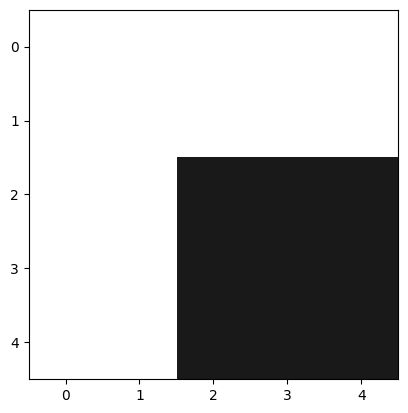

In [4]:
plt.imshow(image, cmap="gray", vmin=0, vmax=100)
plt.show()

In [5]:
# Box blur kernel of size 3x3
kernel = np.ones((3,3)) / 9
print(kernel)
print("sum of weights of the box blur kernel: ", kernel.sum())

[[0.1 0.1 0.1]
 [0.1 0.1 0.1]
 [0.1 0.1 0.1]]
sum of weights of the box blur kernel:  1.0


In [6]:
#top left corner of the window
row, col = 1,1
patch = image[row:row+3, col:col+3]    # the 9 pixels under the window
products = patch * kernel              # cell by cell multiplication
total = products.sum()
print(patch)
print(products)
print(total)

[[100. 100. 100.]
 [100.  10.  10.]
 [100.  10.  10.]]
[[11.1 11.1 11.1]
 [11.1  1.1  1.1]
 [11.1  1.1  1.1]]
60.0


In [7]:
def conv_step(image, kernel, row, col):
    """ one window: patch -> products -> sum"""
    k = kernel.shape[0]
    patch = image[row:row+k, col:col+k]
    products = patch * kernel
    return patch, products, products.sum()

# position of the window (0,0)
conv_step(image, kernel, 0, 0)

(array([[100., 100., 100.],
        [100., 100., 100.],
        [100., 100.,  10.]]),
 array([[11.1, 11.1, 11.1],
        [11.1, 11.1, 11.1],
        [11.1, 11.1,  1.1]]),
 90.0)

In [10]:
# SLIDING THE KERNEL
# 5x5 input image
# 3x3 kernel
# NO padding
# Stride of 1
# -> 3x3

n_out = image.shape[0] - kernel.shape[0] + 1
out = np.zeros((n_out, n_out))

for r in range(n_out):
    for c in range(n_out):
        _, _, out[r,c] = conv_step(image, kernel, r, c)
        print(f"window at position {r}, {c} -> {out[r,c]}")

out

window at position 0, 0 -> 90.0
window at position 0, 1 -> 80.0
window at position 0, 2 -> 70.0
window at position 1, 0 -> 80.0
window at position 1, 1 -> 60.0
window at position 1, 2 -> 40.0
window at position 2, 0 -> 70.0
window at position 2, 1 -> 40.0
window at position 2, 2 -> 10.0


array([[90., 80., 70.],
       [80., 60., 40.],
       [70., 40., 10.]])

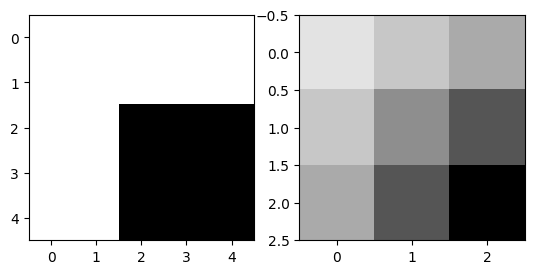

In [11]:
plt.subplot(1,2,1)
plt.imshow(image,'gray',vmin=10, vmax=100)
plt.subplot(1,2,2)
plt.imshow(out, cmap='gray', vmin=10, vmax=100)

In [13]:
def output_size(n, k, padding=0, stride=1):
    return (n + 2*padding - k) // stride + 1

print(output_size(5,3,0,2))

2


In [14]:
def conv2d(image, kernel, padding=0, stride=1, pad_mode="constant"):
    k = kernel.shape[0]

    # 1) padding
    if padding > 0:
        image = np.pad(image, padding, mode=pad_mode)

    # 2) output size (the image is already padded, so padding=0 here)
    n_out = output_size(image.shape[0], k, padding=0, stride=stride)
    out = np.zeros((n_out, n_out))

    # 3) slide the kernel
    for r in range(n_out):
        for c in range(n_out):
            row, col = r * stride, c * stride          # top-left corner of the window
            patch = image[row:row+k, col:col+k]
            out[r, c] = (patch * kernel).sum()
    return out

In [15]:
print(conv2d(image, kernel))                                  # 3x3 -> 90 80 70 ...
print(conv2d(image, kernel, padding=1))                       # 5x5 zero pad -> esquina 44.4
print(conv2d(image, kernel, padding=1, pad_mode="edge"))      # 5x5 mirror -> esquina 100
print(conv2d(image, kernel, stride=2))                        # 2x2 -> 90 70 / 70 10

[[90. 80. 70.]
 [80. 60. 40.]
 [70. 40. 10.]]
[[44.4 66.7 66.7 66.7 44.4]
 [66.7 90.  80.  70.  46.7]
 [66.7 80.  60.  40.  26.7]
 [66.7 70.  40.  10.   6.7]
 [44.4 46.7 26.7  6.7  4.4]]
[[100. 100. 100. 100. 100.]
 [100.  90.  80.  70.  70.]
 [100.  80.  60.  40.  40.]
 [100.  70.  40.  10.  10.]
 [100.  70.  40.  10.  10.]]
[[90. 70.]
 [70. 10.]]


8 kernels in 16.9s


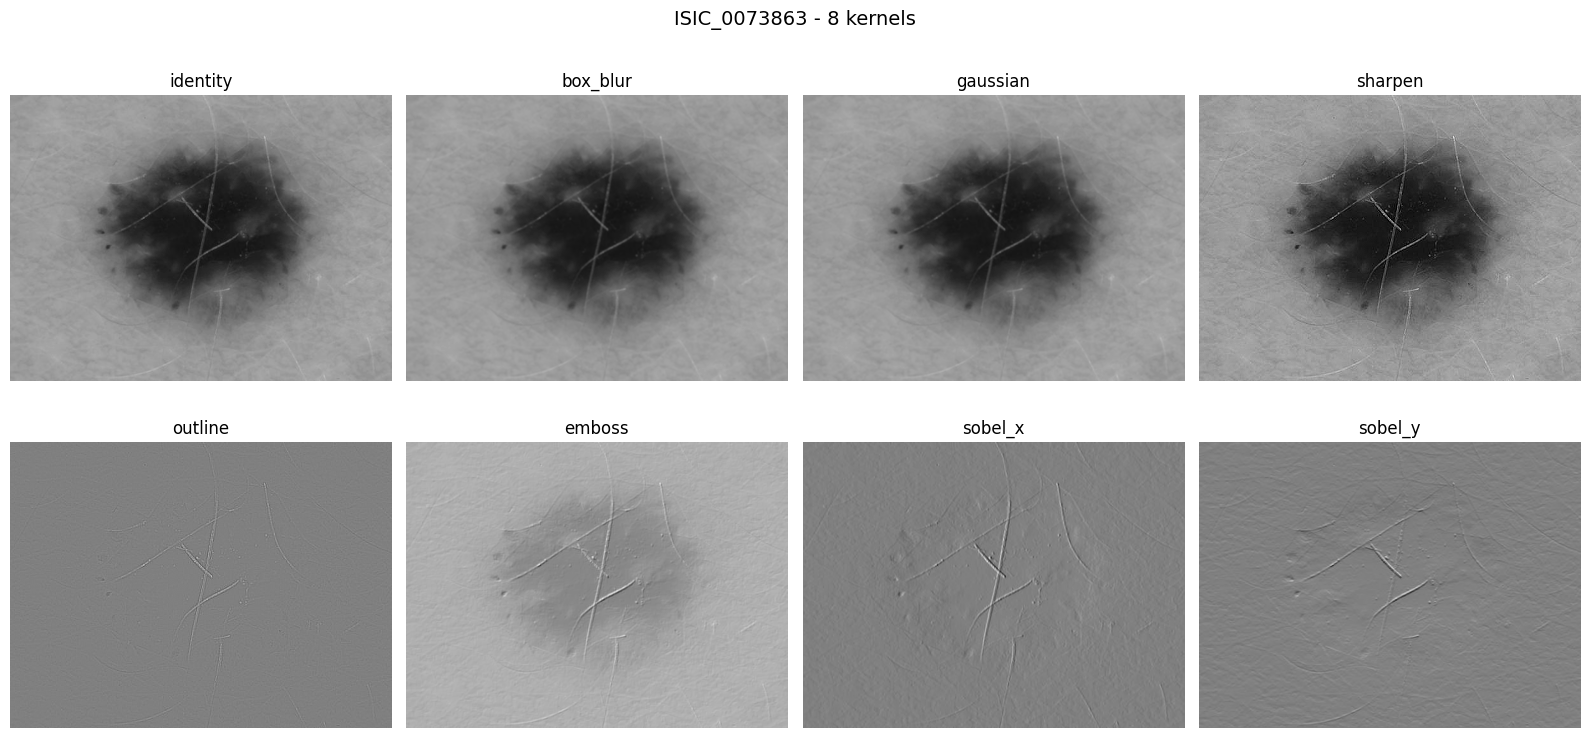

In [ ]:
# Lesion_id -> "ISIC_0073863"
DATA = ROOT.parent / "milk10k_project" / "images"
lesion_id = "ISIC_0073863"
gray = np.array(Image.open(DATA / f"{lesion_id}.jpg").convert("L"), dtype=float)

t0 = time.time()
results = {name: conv2d(gray, K, padding=1, stride=1, pad_mode="edge")
           for name, K in KERNELS.items()}
print(f"8 kernels in {time.time() - t0:.1f}s")


fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (name, res) in zip(axes.flat, results.items()):
    if name in ("identity", "box_blur", "gaussian", "sharpen"):
        ax.imshow(res, cmap="gray", vmin=0, vmax=255)      
        v = np.abs(res).max()
        ax.imshow(res, cmap="gray", vmin=-v, vmax=v)         
    ax.set_title(name)
    ax.axis("off")

fig.suptitle(f"{lesion_id} - 8 kernels", fontsize=14)
plt.tight_layout()
plt.savefig(ROOT / "figures" / f"session4_kernels_{lesion_id}.png", dpi=150)
plt.show()

In [24]:
# NOTE: The original code from class raised
#   TypeError: conv2d() missing 1 required positional argument: 'stride'
# because my conv2d() had no default value for `stride`.
# Fix: redefined conv2d() here with stride=1 as default, so the professor's
# call conv2d(image, kernel, padding=1, pad_mode="symmetric") works unchanged.

def conv2d(image, kernel, padding, stride=1, pad_mode="constant"):
    k = kernel.shape[0]
    padded = np.pad(image, padding, mode=pad_mode)
    out_h = output_size(image.shape[0], k, padding, stride)
    out_w = output_size(image.shape[1], k, padding, stride)
    out = np.zeros((out_h, out_w))
    for r in range(out_h):
        for c in range(out_w):
            row, col = r * stride, c * stride
            patch = padded[row:row+k, col:col+k]
            out[r, c] = (patch * kernel).sum()
    return out


def fast_conv2d(image, kernel):
    """Same as conv2d(..., padding=1, pad_mode="symmetric") but in optimized C."""
    from scipy import ndimage
    return ndimage.correlate(image, kernel, mode="reflect")


t0 = time.perf_counter()
slow = conv2d(image, KERNELS["box_blur"], padding=1, pad_mode="symmetric")
t_slow = time.perf_counter() - t0
t0 = time.perf_counter()
fast = fast_conv2d(image, KERNELS["box_blur"])
t_fast = time.perf_counter() - t0
print(f"loops {t_slow:.3f}s | scipy {t_fast:.4f}s | {t_slow / t_fast:.0f}x faster")
print("same result:", np.allclose(slow, fast))

loops 0.000s | scipy 0.0001s | 3x faster
same result: True
